# sub-05: design certainty and eye labels (v2)

**v2**: bars B is read from `derivatives/vdm/sub-14/` or, during the design-A refit, from `derivatives/vdm/_hold/sub-14/`.

**Why**: with the new fits, sub-05 (strabismic, right amblyopic eye, ΔlogMAR 0.70) prefers its *amblyopic* eye in every ROI, and its "amblyopic" eye has a better pRF R² than its "fellow" eye.

**Documents** (sourcedata/A/sm):
- runs 5-8 → BIDS RightEye, aborted run 9, anatomy 10, runs 11-14 → BIDS LeftEye (participant-mapping: "RIGHT eye first");
- the original readme of the session describes one scan only: `bars_blanks0_LEFT`, listed with file 11. Files are listed alphabetically. "blanks0" = bars without blanks = B, and the data say that the only B run is **file 05** (first run of the session).
  - If the description belongs to file 05, the first block was the **left** eye and the labels are swapped.
  - Read literally (file 11 = left), it supports the current labels but contradicts "blanks0".
- outside the scanner, the right eye fixates less stably (Supplementary Fig. 6, S5): consistent with a right amblyopic eye. This is the clinical eye, not the label of the MRI runs.

**Tests**
- **A. Design of each run of sub-05** (8 runs): every candidate stimulus (bars A, bars B, rings, wedges; shifted ±1-2 TR, flipped, time-reversed). For bars runs, the pRFs come from the RingsWedges fit; for rings / wedges runs, from the BarsBars fit. Either way the pRFs never come from the run tested. Both eyes' pRFs are used.
- **B. Run-level consistency** (per-run GLM betas from `od_glm_common_cache`): do the 4 runs of each labelled eye form two clusters? A single mislabelled run would group with the other eye. Compared with the other subjects.
- **C. Signatures of the amblyopic eye**, compared with the 10 other amblyopes:
  - pRF R² (BarsBars and RingsWedges fits, separately);
  - effective pRF size σ/√n;
  - consistency of the pRF positions between two independent data sets of the same eye (BarsBars vs RingsWedges fits);
  - response amplitude.

  If sub-05's "amblyopic" eye has the profile of the other amblyopes' **fellow** eye on every independent signature, a swap of the two blocks becomes the simplest explanation.

**Limits**: no fMRI test can prove which eye is the left one. Tests B-C give converging evidence; the decision must combine it with the documents. Read only.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, sys, glob, math
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex

main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
vdm_dir = '{}/{}/derivatives/vdm'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
glm_cache_dir = '{}/od_glm_common_cache'.format(fig_dir)
cache_dir = '{}/sub05_eye_cache'.format(fig_dir)
os.makedirs(cache_dir, exist_ok=True)

base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in ["settings.yml", "prf-analysis.yml"]])
analysis_info = settings[0]
patients = analysis_info['group-patient']
controls = analysis_info['group-control']
maps = analysis_info['maps_names_css']
set_pycortex_config_file('{}/cortex'.format(pp_dir))

participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e).split(' ')[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)
             if str(e).split(' ')[0] in ('L', 'R')}
eyes = {'L': 'LeftEye', 'R': 'RightEye'}
rois_v13 = ['V1', 'V2', 'V3']
TR, T = 2.0, 120


def deriv_fn(subject, task, hemi):
    return '{}/{}/fsnative/prfmodel/prf_derivatives/{}_task-{}_hemi-{}_fmriprep_dct_psc_concat_prf-css_deriv.func.gii'.format(
        pp_dir, subject, subject, task, hemi)


def load_deriv(subject, task):
    """pRF derivatives of a task (both hemispheres), cached locally: dict of full-length arrays."""
    fn = '{}/{}_{}_deriv.npz'.format(cache_dir, subject, task)
    if not os.path.isfile(fn):
        d = load_surface_pycortex(L_fn=deriv_fn(subject, task, 'L'), R_fn=deriv_fn(subject, task, 'R'))['data_concat']
        np.savez_compressed(fn, **{k: d[maps.index(k)].astype(np.float32) for k in
                                   ['prf_rsq', 'prf_ecc', 'prf_size', 'prf_n', 'amplitude', 'prf_x', 'prf_y']})
    z = np.load(fn)
    return {k: z[k].astype(float) for k in z.files}


def load_rois(subject):
    fn = '{}/{}_rois.npz'.format(cache_dir, subject)
    if not os.path.isfile(fn):
        r = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp', mask=True, rois=None, hemis=None)
        np.savez_compressed(fn, **{k: r[k] for k in ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']})
    z = np.load(fn)
    return {k: z[k].astype(bool) for k in z.files}

## A. Design of each run of sub-05

In [2]:
subject = 'sub-05'
common = np.load('{}/task-BarsBarsRingsWedgesLeftEye_vdm.npy'.format(vdm_dir))
stims = {'bars A': common[..., :120], 'rings': common[..., 240:360], 'wedges': common[..., 360:480],
         'bars B': np.load(next(f for f in ['{}/sub-14/sub-14_task-BarsBarsLeftEye_vdm.npy'.format(vdm_dir),
                                             '{}/_hold/sub-14/sub-14_task-BarsBarsLeftEye_vdm.npy'.format(vdm_dir)]
                                if os.path.isfile(f)))[..., :120]}       # sub-14 design folder may be in _hold during the design-A refit
candidates = {}
for name, s in stims.items():
    candidates[name] = s
    for sh in [-2, -1, 1, 2]:
        candidates['{} shift {:+d} TR'.format(name, sh)] = np.roll(s, sh, axis=2)
    candidates[name + ' flip up/down'] = s[::-1]
    candidates[name + ' flip left/right'] = s[:, ::-1]
    candidates[name + ' time-reversed'] = s[..., ::-1]

t_ = np.arange(0, 32, TR)
g = lambda a: t_ ** (a - 1) * np.exp(-t_) / math.gamma(a)
H = g(6) - g(16) / 6; H /= H.sum()


def conv_hrf(d):
    return np.apply_along_axis(lambda v: np.convolve(v, H)[:T], 0, d)


def zc(a):
    return (a - a.mean(0)) / (a.std(0) + 1e-9)


def score(stim, y, P, pix):
    x0, y0, sd, n = P
    rr, cc = np.meshgrid(np.arange(50) - 24.5, np.arange(50) - 24.5, indexing='ij')
    X, Y = (cc * pix).ravel(), (-rr * pix).ravel()
    G = np.exp(-((X[:, None] - x0) ** 2 + (Y[:, None] - y0) ** 2) / (2 * sd ** 2))
    p = conv_hrf(np.clip(np.moveaxis(stim, -1, 0).reshape(T, -1) @ G, 0, None) ** n)
    return max(float(np.median((zc(np.roll(p, sh, 0)) * zc(y)).mean(0))) for sh in range(-2, 3))


def run_data(subject, run):
    fns = ['{}/{}/fsnative/func/fmriprep_dct_psc/{}_ses-01_task-{}_hemi-{}_space-fsnative_fmriprep_dct_psc_bold.func.gii'.format(
        pp_dir, subject, subject, run, h) for h in 'LR']
    d = load_surface_pycortex(L_fn=fns[0], R_fn=fns[1])['data_concat']
    return d if d.shape[0] == T else d.T

rois = load_rois(subject)
v13 = rois['V1'] | rois['V2'] | rois['V3']
prf_sets = {eye: {'RingsWedges': load_deriv(subject, 'RingsWedges' + eye), 'BarsBars': load_deriv(subject, 'BarsBars' + eye)}
            for eye in eyes.values()}

# pixel size: the new fits use the screen width (fake_screen_size_cm); choose the scale that best fits a known run
scales = {'screen height (old fits)': 2 * math.degrees(math.atan(50.6 / 2 / 242)) / 50,
          'screen width (new fits)': 2 * math.degrees(math.atan(67.9 / 2 / 242)) / 50}


def params(d, mask):
    return (d['prf_x'][mask], d['prf_y'][mask], np.clip(d['prf_size'][mask], 0.2, None), np.clip(d['prf_n'][mask], 0.05, 1))

y_ref = run_data(subject, 'BarsLeftEye_run-02')
d_ref = prf_sets['LeftEye']['RingsWedges']
m_ref = v13 & (d_ref['prf_rsq'] > 0.2) & np.isfinite(y_ref).all(0) & (y_ref.std(0) > 0)
scale_scores = {k: score(stims['bars A'], y_ref[:, m_ref], params(d_ref, m_ref), v) for k, v in scales.items()}
pix = scales[max(scale_scores, key=scale_scores.get)]
print('scale check on BarsLeftEye run-02 (A):', {k: round(v, 3) for k, v in scale_scores.items()}, '-> using', max(scale_scores, key=scale_scores.get))

runs = ['BarsRightEye_run-01', 'BarsRightEye_run-02', 'RingsRightEye_run-01', 'WedgesRightEye_run-01',
        'BarsLeftEye_run-01', 'BarsLeftEye_run-02', 'RingsLeftEye_run-01', 'WedgesLeftEye_run-01']
rows = []
for run in runs:
    y = run_data(subject, run)
    prf_task = 'RingsWedges' if run.startswith('Bars') else 'BarsBars'      # pRFs never estimated on the run tested
    for eye in eyes.values():
        d = prf_sets[eye][prf_task]
        m = v13 & (d['prf_rsq'] > 0.2) & np.isfinite(y).all(0) & (y.std(0) > 0)
        sc = {name: score(s, y[:, m], params(d, m), pix) for name, s in candidates.items()}
        best = sorted(sc, key=sc.get, reverse=True)
        rows.append({'run (BIDS)': run, 'pRFs from': '{} {}'.format(prf_task, eye), 'best': best[0], 'r best': sc[best[0]],
                     '2nd': best[1], 'r 2nd': sc[best[1]],
                     'r bars A': sc['bars A'], 'r bars B': sc['bars B'], 'r rings': sc['rings'], 'r wedges': sc['wedges']})
    print(run, 'done', flush=True)
designA = pd.DataFrame(rows)
pd.set_option('display.width', 250)
print(designA.round(3).to_string(index=False))

scale check on BarsLeftEye run-02 (A): {'screen height (old fits)': 0.459, 'screen width (new fits)': 0.455} -> using screen height (old fits)
BarsRightEye_run-01 done
BarsRightEye_run-02 done
RingsRightEye_run-01 done
WedgesRightEye_run-01 done
BarsLeftEye_run-01 done
BarsLeftEye_run-02 done
RingsLeftEye_run-01 done
WedgesLeftEye_run-01 done
           run (BIDS)            pRFs from                  best  r best                2nd  r 2nd  r bars A  r bars B  r rings  r wedges
  BarsRightEye_run-01  RingsWedges LeftEye                bars B   0.467 bars B shift +1 TR  0.464     0.148     0.467    0.178     0.076
  BarsRightEye_run-01 RingsWedges RightEye                bars B   0.500 bars B shift -1 TR  0.499     0.161     0.500    0.214     0.061
  BarsRightEye_run-02  RingsWedges LeftEye    bars A shift -1 TR   0.516             bars A  0.515     0.515     0.183    0.147     0.131
  BarsRightEye_run-02 RingsWedges RightEye    bars A shift -1 TR   0.546 bars A shift -2 TR  0.545     

## B. Run-level consistency (per-run betas)

For each run r and labelled eye e: β(e, r) = Σxy / Σx² (from `od_glm_common_cache`, common regressor of run r). Each vertex's 8 betas are divided by their mean (to remove the overall responsiveness of the vertex); the correlation between runs, across the good vertices of V1-V3, then reflects the eye-specific pattern (ocular dominance columns, eye-specific responsiveness).

**Expected**: the 4 runs of an eye correlate more with each other than with the runs of the other eye. A mislabelled run groups with the other eye. This test checks the **consistency** of the labels within the session; it cannot detect a swap of the two whole blocks (both blocks would still be internally consistent).

subject   group  eye separation least consistent run  its separation
 sub-18 control          -0.057             R Bars02          -0.381
 sub-04 patient          -0.052             L Wedges          -0.329
 sub-14 control          -0.031             L Wedges          -0.111
 sub-20 control           0.008             L Wedges          -0.119
 sub-12 patient           0.013             R Bars02          -0.133
 sub-21 control           0.026             L Wedges          -0.427
 sub-19 control           0.029             R Bars01          -0.233
 sub-13 control           0.058             L Wedges          -0.393
 sub-17 control           0.122             R Wedges          -0.140
 sub-11 patient           0.146             L Bars02          -0.313
 sub-16 control           0.172             L Bars01           0.019
 sub-01 patient           0.202             R Bars01           0.011
 sub-03 patient           0.204              R Rings          -0.028
 sub-08 patient           0.216   

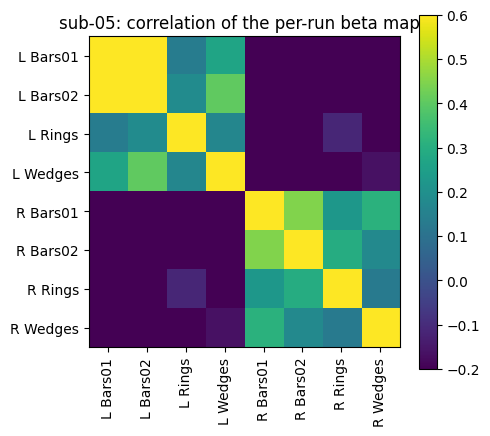

sub-05, per run (within-eye minus between-eye correlation): {'L Bars01': 0.803, 'L Bars02': 0.914, 'L Rings': 0.579, 'L Wedges': 0.738, 'R Bars01': 0.776, 'R Bars02': 0.763, 'R Rings': 0.71, 'R Wedges': 0.625}


In [3]:
run_names = ['Bars01', 'Bars02', 'Rings', 'Wedges']


def run_betas(subject):
    z = np.load('{}/{}_od-glm-common_runs.npz'.format(glm_cache_dir, subject))
    sxy, sxx = z['sxy_common'], z['sxx_common']
    roi = z['roi']
    rsq = (z['fit_L'][8] + z['fit_R'][8]) / 2 if z['fit_L'].shape[0] > 8 else None
    with np.errstate(divide='ignore', invalid='ignore'):
        b = sxy / sxx[None]                                    # (eye, run, vertex), eye 0 = left, 1 = right
    return b, roi, rsq


def eye_clustering(subject):
    b, roi, rsq = run_betas(subject)
    m = np.isin(roi, rois_v13) & np.all(np.isfinite(b.reshape(8, -1)), axis=0)
    if rsq is not None:
        m &= rsq > np.nanpercentile(rsq[m], 50)
    B = b.reshape(8, -1)[:, m]
    B = B / np.mean(B, axis=0, keepdims=True)
    C = np.corrcoef(B)
    labels = ['L ' + r for r in run_names] + ['R ' + r for r in run_names]
    same = np.array([[(i < 4) == (j < 4) and i != j for j in range(8)] for i in range(8)])
    diff = np.array([[(i < 4) != (j < 4) for j in range(8)] for i in range(8)])
    # for each run: mean correlation with the other runs of its labelled eye minus with the runs of the other eye
    per_run = {labels[i]: np.mean(C[i][same[i]]) - np.mean(C[i][diff[i]]) for i in range(8)}
    return C, labels, np.mean(C[same]) - np.mean(C[diff]), per_run

rows, mats = [], {}
for s in patients + controls:
    if not os.path.isfile('{}/{}_od-glm-common_runs.npz'.format(glm_cache_dir, s)):
        continue
    C, labels, sep, per_run = eye_clustering(s)
    mats[s] = C
    rows.append({'subject': s, 'group': 'patient' if s in patients else 'control', 'eye separation': sep,
                 'least consistent run': min(per_run, key=per_run.get), 'its separation': min(per_run.values())})
clust = pd.DataFrame(rows).sort_values('eye separation')
print(clust.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(mats['sub-05'], vmin=-0.2, vmax=0.6, cmap='viridis')
ax.set_xticks(range(8)); ax.set_xticklabels(labels, rotation=90); ax.set_yticks(range(8)); ax.set_yticklabels(labels)
ax.set_title('sub-05: correlation of the per-run beta maps')
plt.colorbar(im, ax=ax); plt.tight_layout()
fig.savefig('{}/sub05_run_clustering.pdf'.format(fig_dir), bbox_inches='tight'); plt.show()
_, _, _, pr05 = eye_clustering('sub-05')
print('sub-05, per run (within-eye minus between-eye correlation):', {k: round(v, 3) for k, v in pr05.items()})

## C. Signatures of the amblyopic eye (labelled AE vs FE), sub-05 vs the other amblyopes

Each index is a ratio (or difference) labelled-AE / labelled-FE on V1-V3 vertices. For the other amblyopes the labels are taken as correct: their distribution says what an amblyopic eye usually looks like in these data. Independent signatures:
1. pRF R², **RingsWedges** fit;
2. pRF R², **BarsBars** fit (other runs);
3. effective pRF size σ/√n (vertices good in both eyes);
4. **within-eye position consistency**: distance between the pRF centres of the BarsBars and RingsWedges fits of the same eye (independent runs), relative to eccentricity;
5. pRF amplitude (BarsBarsRingsWedges fit).

Where ratio < 1 is the typical amblyope profile for an index (or > 1), a swapped sub-05 would sit on the other side, under its labels.

         R2 RingsWedges AE/FE  R2 BarsBars AE/FE  size sigma/sqrt(n) AE/FE  amplitude AE/FE  position inconsistency AE/FE  n good
subject                                                                                                                          
sub-01                  0.907              1.279                     1.068            1.014                         1.389    9565
sub-02                  0.678              0.833                     1.131            0.927                         0.902    6649
sub-03                  0.771              0.751                     1.163            0.627                         0.954    4286
sub-04                  1.474              0.890                     0.849            0.951                         1.525     693
sub-05                  1.268              1.145                     0.951            1.237                         0.849    5935
sub-06                  0.915              1.156                     1.196            0.91

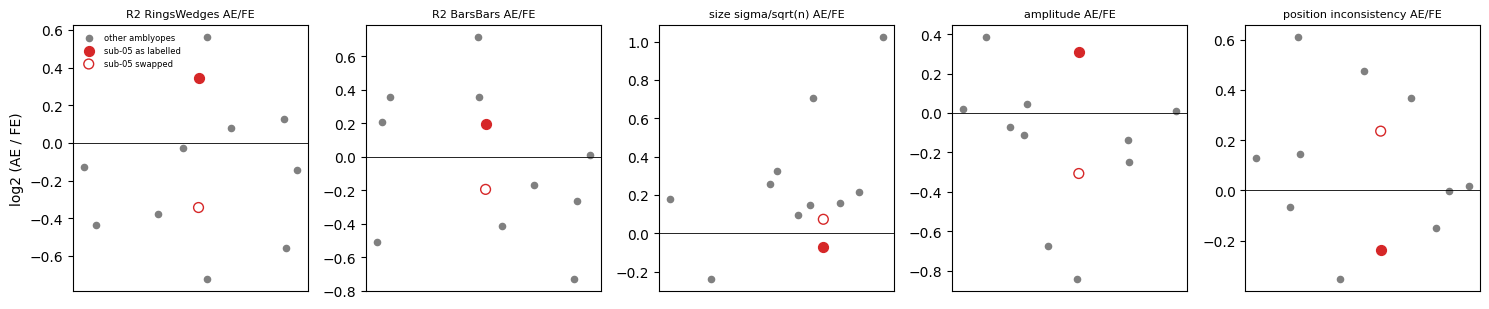

In [4]:
def signature(subject):
    ae = ambly_eye[subject]; fe = 'R' if ae == 'L' else 'L'
    rois = load_rois(subject)
    v13 = rois['V1'] | rois['V2'] | rois['V3']
    D = {e: {t: load_deriv(subject, t + eyes[e]) for t in ['RingsWedges', 'BarsBars', 'BarsBarsRingsWedges']} for e in 'LR'}
    out = {'subject': subject}
    for t in ['RingsWedges', 'BarsBars']:
        out['R2 {} AE/FE'.format(t)] = np.nanmedian(D[ae][t]['prf_rsq'][v13]) / np.nanmedian(D[fe][t]['prf_rsq'][v13])
    full = 'BarsBarsRingsWedges'
    good = v13 & (D[ae][full]['prf_rsq'] > 0.2) & (D[fe][full]['prf_rsq'] > 0.2)
    eff = {e: D[e][full]['prf_size'] / np.sqrt(np.clip(D[e][full]['prf_n'], 0.05, None)) for e in 'LR'}
    out['size sigma/sqrt(n) AE/FE'] = np.nanmedian(eff[ae][good] / eff[fe][good])
    out['amplitude AE/FE'] = np.nanmedian(D[ae][full]['amplitude'][good] / D[fe][full]['amplitude'][good])
    cons = {}
    for e in 'LR':
        a, b = D[e]['BarsBars'], D[e]['RingsWedges']
        m = v13 & (a['prf_rsq'] > 0.2) & (b['prf_rsq'] > 0.2)
        dist = np.hypot(a['prf_x'][m] - b['prf_x'][m], a['prf_y'][m] - b['prf_y'][m])
        ecc = (a['prf_ecc'][m] + b['prf_ecc'][m]) / 2
        cons[e] = np.nanmedian(dist / np.clip(ecc, 0.5, None))
    out['position inconsistency AE/FE'] = cons[ae] / cons[fe]
    out['n good'] = int(good.sum())
    return out

sig = pd.DataFrame([signature(s) for s in patients]).set_index('subject')
cols = [c_ for c_ in sig.columns if c_ != 'n good']
others = sig.drop(index='sub-05')
summary = pd.DataFrame({'others median': others[cols].median(),
                        'others: % with ratio < 1': (others[cols] < 1).mean() * 100,
                        'sub-05 (labels as is)': sig.loc['sub-05', cols],
                        'sub-05 (labels swapped)': 1 / sig.loc['sub-05', cols]})
summary['rank of sub-05 among the 11 (1 = lowest)'] = [int((sig[c_] < sig.loc['sub-05', c_]).sum()) + 1 for c_ in cols]
print(sig.round(3).to_string())
print()
print(summary.round(3).to_string())

fig, axes = plt.subplots(1, len(cols), figsize=(3 * len(cols), 3.2))
for ax, c_ in zip(axes, cols):
    v = np.log2(others[c_].values)
    ax.scatter(np.zeros_like(v) + np.random.uniform(-0.1, 0.1, len(v)), v, color='grey', s=20, label='other amblyopes')
    ax.scatter([0], [np.log2(sig.loc['sub-05', c_])], color='tab:red', s=50, label='sub-05 as labelled')
    ax.scatter([0], [-np.log2(sig.loc['sub-05', c_])], color='tab:red', s=50, facecolors='none', label='sub-05 swapped')
    ax.axhline(0, color='k', lw=0.6); ax.set_xticks([]); ax.set_title(c_, fontsize=8)
axes[0].set_ylabel('log2 (AE / FE)')
axes[0].legend(fontsize=6, frameon=False)
plt.tight_layout()
fig.savefig('{}/sub05_eye_signatures.pdf'.format(fig_dir), bbox_inches='tight'); plt.show()

## How to read

- **A**: for every run, the best candidate must be its labelled stimulus (bars A or B, rings, wedges), with both eyes' pRFs, and a clear margin over the 2nd. It confirms (or not) the design and the task labels of all 8 runs. BarsRightEye run-01 must come out as bars B.
- **B**: sub-05's eye separation compared with the other subjects. A low or negative per-run value for one run means that this run does not look like the other runs of its labelled eye.
- **C**: sub-05 "as labelled" vs "swapped" against the distribution of the other amblyopes, for each signature. A swap is supported if the swapped sub-05 falls inside the usual amblyope range on most of the independent signatures (R² of the two fits, size, consistency), while as labelled it falls on the opposite side.

The final decision combines A-C with the documents (readme `bars_blanks0_LEFT`, participant-mapping). If the swap is supported, the two blocks of sub-05 are swapped and its OD recomputed (like sub-10). Otherwise, sub-05 is kept as a real case of amblyopic-eye preference.